## Question 01 – Network of my interest

**The network I care about most** is the **career network of artists who have exhibited at the Venice Biennale** (1895–2026), and in particular how artists from the Global South (GS) move into Global North (GN) institutions.

**(a) Nodes and links**

**Nodes** are exhibition venues: museums, galleries, biennials, art fairs and other institutions. Each node carries attributes: its country, its GN/GS status, and the primary language(s) of that country.

**Links** come from artists' careers. When an artist exhibits at institution *A* and then at institution *B*, this creates a directed link *A → B*. The result is a **directed, weighted, time-stamped network** in which individual careers become flows between institutions. Artists are not nodes: their attributes travel on the links they create.

Every link falls into one of four transition types: GN→GN, GN→GS, GS→GS and GS→GN. The key event I want to track is the **GS→GN transition**, meaning an artist's first appearance at a Global North venue after showing mainly in the Global South. A special case is when that first GN appearance *is* the Venice Biennale itself, which lets me ask whether Venice works as a gateway or only as a moment of visibility.

**Language enters on both sides.** Institutions get the language(s) of the country where they are located. Artists get the language(s) of their place of birth, and that information is carried by their links. This lets me ask whether GS→GN transitions follow **linguistic corridors**, such as Afro-Francophone artists moving toward Paris or Lusophone artists toward Lisbon. It also lets me ask whether they follow **colonial corridors**, and whether either explains the flows better than the simple GN/GS binary, geography or market size.

**(b) Size**

The Biennale has run since 1895, which gives roughly **61 editions** of the International Art Exhibition. The Biennale's ASAC archive lists about **19,000 participating artists** across the international exhibition and the national pavilions. About **11,000–16,000 of these artists** can be matched to full exhibition histories in Artfacts and Artnet, depending on the matching criteria.

Projected onto institutions, the career network has **11,397 institution nodes** and **98,816 directed links**, spread across **[N] countries**.

The Biennale works as a **seed sample** of a much larger global art-world network, which is far too large to observe directly.

**(c) Can it be mapped?**

Largely yes, and I have already done much of it. I built the dataset during my MFA thesis by scraping **Artfacts** and **Artnet** and combining them with the Biennale's own **ASAC archive**. I am now extending the ASAC side with a scraper that collects every artwork record, including title, technique, artist nationality, edition and pavilion.

The limits matter as much as the map:

- **Uneven coverage.** Global North institutions are much better documented than Global South ones. GS institutions are therefore only a small share of the network, which is dominated by GN venues. GS institutions are the minority I want to study, and the data systematically under-represents them.
- **Sparse early decades.** P1 has only 331 institutions, against 10,890 in P4.
- **Messy identities.** Artist names vary across languages and transliterations, and an institution's language has to be inferred from its country.

So the network can be mapped, but the gaps are not random. Part of the project is **measuring that bias rather than ignoring it**.

To build the colonial and linguistic layer, I am adding **CEPII GeoDist**. This dataset gives, for every pair of countries, whether they share an official language or a widely spoken language, whether they ever had a colonial relationship, and whether they shared a colonizer. It also gives their geographic distance and whether they share a border. Joining it to the country of the origin and destination institution of each link lets me classify every transition as **linguistic, colonial, both, or neither**. Distance then works as a baseline to compare against.

**(d) Why I care**

I come from art history and information design, and I have always been struck that the art world presents itself as global while its circulation looks very structured. Venice is supposed to be a place where artists from anywhere become visible, but visibility at the Biennale does not guarantee access to the institutions that build long careers.

A network view lets me ask whether there are recurring paths, gatekeeping venues, or shared-language channels that make some transitions easier than others. It also lets me ask whether those patterns have changed across more than a century of Biennale history, from the colonial era through decolonization to today's "global" art world.

## Question 02 – Matrix Formalism

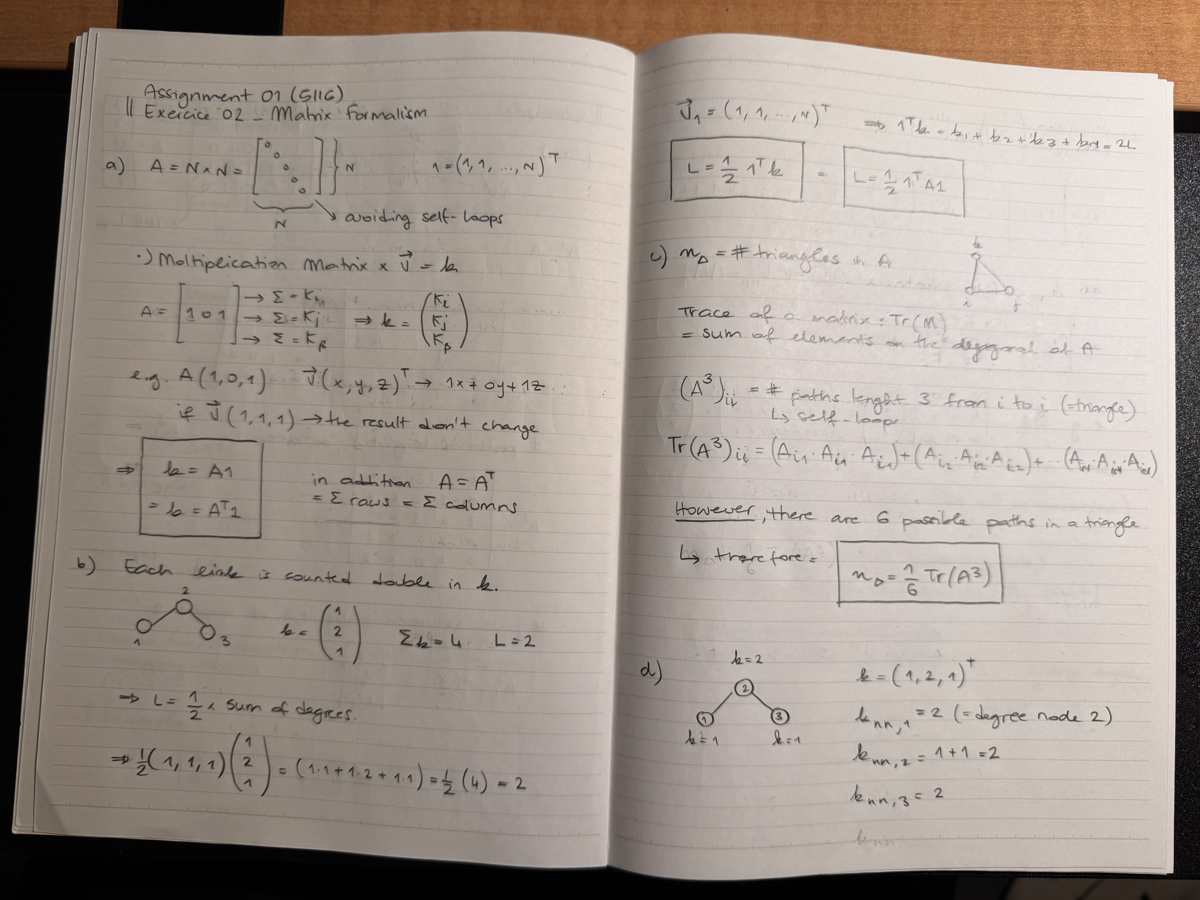

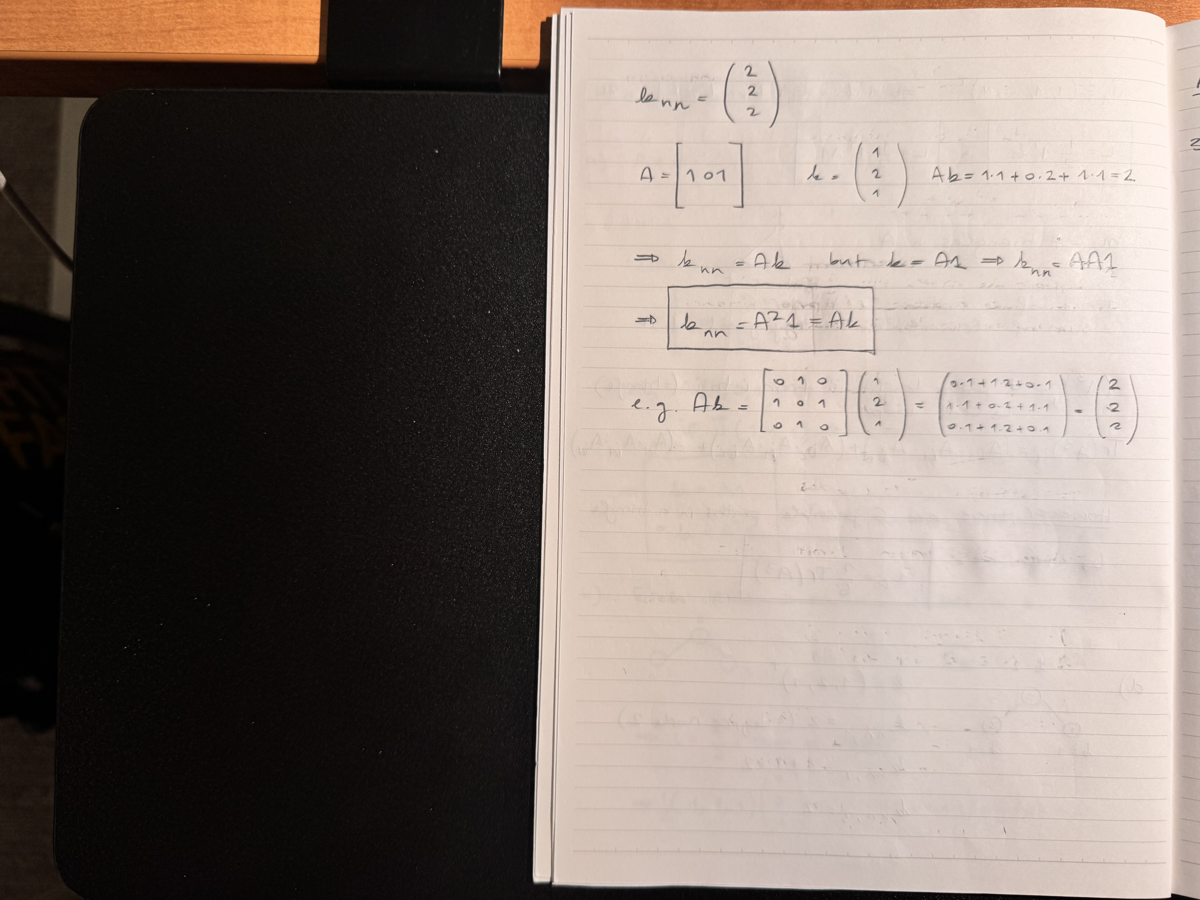

In [36]:
from PIL import Image
from pillow_heif import register_heif_opener
from IPython.display import display

register_heif_opener()   # lets PIL open .HEIC files

folder = "/Users/jac/Library/Mobile Documents/com~apple~CloudDocs/Desktop/PHD/CLASSES/FALL_2026/NETS5116/01_Assignment/"
files = ["IMG_5697.HEIC", "IMG_5698.HEIC"]

for f in files:
    img = Image.open(folder + f)
    img.thumbnail((1200, 1200))   # resize so it fits in the notebook
    display(img)

## Question 03_ Visualisation

In [31]:
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

In [32]:
# Import netscience.gml from the same folder
G = nx.read_gml('netscience.gml')
print(G)


Graph with 1589 nodes and 2742 edges


19 communities found; modularity = 0.850


/var/folders/hz/8_pbd_z510s72pvrq_72td3c0000gn/T/ipykernel_19156/781181707.py:87: DeprecationWarning: `alltrue` is deprecated as of NumPy 1.25.0, and will be removed in NumPy 2.0. Please use `all` instead.
  nx.draw_networkx_edges(G_lcc, pos, edgelist=[(u, v) for u, v, _ in edges],


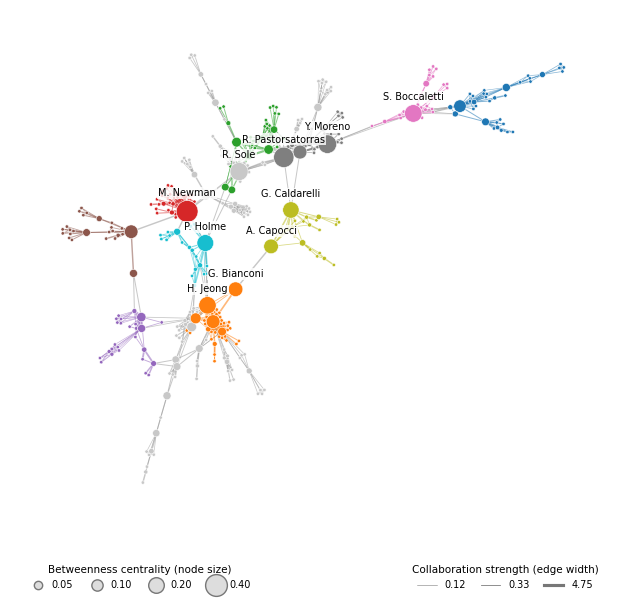


Author                 Betweenness  Degree  Community
M. Newman                    0.397      27          3
R. Pastorsatorras            0.345      15          7
Y. Moreno                    0.286      14          7
R. Sole                      0.270      17         12
S. Boccaletti                0.255      19          6
H. Jeong                     0.251      27          1
P. Holme                     0.232      14          9
G. Caldarelli                0.222      12          8
G. Bianconi                  0.175       4          1
A. Capocci                   0.175       6          8


In [33]:
# Journal-style defaults
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 8,
    "legend.fontsize": 7,
    "legend.title_fontsize": 7.5,
    "pdf.fonttype": 42,        
    "svg.fonttype": "none",    
})
FIG_INCHES = 7.0               

# Largest connected component
largest_cc = max(nx.connected_components(G), key=len)
G_lcc = G.subgraph(largest_cc).copy()
nodes_list = list(G_lcc.nodes())

# Betweenness (unweighted) -> node size
betweenness = nx.betweenness_centrality(G_lcc)
bc = np.array([betweenness[n] for n in nodes_list])
SIZE_MIN, SIZE_SCALE = 6, 600          # marker area in points^2
node_sizes = SIZE_MIN + SIZE_SCALE * bc

# Communities (Louvain, weighted by collaboration strength) -> node color
communities = nx.community.louvain_communities(G_lcc, weight="value", seed=42)
communities = sorted(communities, key=len, reverse=True)
community_of = {n: i for i, c in enumerate(communities) for n in c}

N_COLORED = 10                                   # color the 10 largest communities
palette = plt.get_cmap("tab10").colors
OTHER = "#c8c8c8"                                # small communities in light gray
node_colors = [palette[community_of[n]] if community_of[n] < N_COLORED else OTHER
               for n in nodes_list]
print(f"{len(communities)} communities found; "
      f"modularity = {nx.community.modularity(G_lcc, communities, weight='value'):.3f}")

# Edge width on a log scale (weights are highly skewed)
edges = list(G_lcc.edges(data=True))
weights = np.array([d.get("value", 1) for _, _, d in edges])
W_MIN, W_SCALE = 0.25, 2.0
def edge_width(w):
    return W_MIN + W_SCALE * np.log1p(w) / np.log1p(weights.max())
edge_widths = edge_width(weights)

# Edges inside a colored community take that community's color; others gray
edge_colors = []
for u, v, _ in edges:
    cu, cv = community_of[u], community_of[v]
    edge_colors.append(palette[cu] if (cu == cv and cu < N_COLORED) else "#9a9a9a")


# Spring layout + overlap removal
pos = nx.spring_layout(G_lcc, weight="value", seed=42, iterations=300)

def remove_overlaps(xy, sizes, fig_inches, padding=1.3, n_iter=300):
    """Push apart nodes whose drawn circles overlap."""
    xy = xy.copy()
    span = (xy.max(axis=0) - xy.min(axis=0)).max()
    radius = np.sqrt(sizes) / 2 / (fig_inches * 72) * span * padding
    for _ in range(n_iter):
        diff = xy[:, None, :] - xy[None, :, :]
        dist = np.linalg.norm(diff, axis=-1)
        np.fill_diagonal(dist, np.inf)
        overlap = np.clip(radius[:, None] + radius[None, :] - dist, 0, None)
        if overlap.max() < 1e-6:
            break
        direction = diff / np.where(dist == 0, 1e-9, dist)[..., None]
        xy += (direction * (overlap / 2)[..., None]).sum(axis=1)
    return xy

xy = remove_overlaps(np.array([pos[n] for n in nodes_list]), node_sizes, FIG_INCHES)
pos = dict(zip(nodes_list, xy))


# Labels: top 10 by betweenness
def pretty_name(raw):
    surname, _, initials = raw.partition(", ")
    return f"{initials}. {surname.title()}" if initials else raw.title()

top_nodes = sorted(betweenness, key=betweenness.get, reverse=True)[:10]

# Manual offsets (in points) to fix individual label collisions if needed
LABEL_OFFSETS = {}   # e.g. {"MORENO, Y": (12, -4)}

# Draw
fig, ax = plt.subplots(figsize=(FIG_INCHES, FIG_INCHES * 0.85))

nx.draw_networkx_edges(G_lcc, pos, edgelist=[(u, v) for u, v, _ in edges],
                       width=edge_widths, edge_color=edge_colors,
                       alpha=0.55, ax=ax)

# Draw small nodes first so large hubs sit on top
order = np.argsort(node_sizes)
ax.scatter(xy[order, 0], xy[order, 1], s=node_sizes[order],
           c=[node_colors[i] for i in order],
           edgecolors="white", linewidths=0.4, zorder=3)

for n in top_nodes:
    i = nodes_list.index(n)
    r_pts = np.sqrt(node_sizes[i]) / 2
    dx, dy = LABEL_OFFSETS.get(n, (0, r_pts + 2))   # default: just above the node
    ax.annotate(pretty_name(n), xy=pos[n], xytext=(dx, dy),
                textcoords="offset points", ha="center", va="bottom",
                fontsize=7, zorder=4,
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=0.8))

ax.set_aspect("equal")
ax.axis("off")

#Legends, placed below the network (outside the drawing area)
size_values = [v for v in [0.05, 0.1, 0.2, 0.4] if v <= bc.max() * 1.05]
size_handles = [Line2D([], [], marker="o", linestyle="", markerfacecolor="#dddddd",
                       markeredgecolor="#777777",
                       markersize=np.sqrt(SIZE_MIN + SIZE_SCALE * v))
                for v in size_values]

edge_values = [weights.min(), np.median(weights), weights.max()]
edge_handles = [Line2D([], [], color="#777777", lw=edge_width(w)) for w in edge_values]

leg1 = fig.legend(size_handles, [f"{v:.2f}" for v in size_values],
                  title="Betweenness centrality (node size)",
                  loc="lower left", bbox_to_anchor=(0.08, 0.0),
                  ncol=len(size_values), frameon=False,
                  columnspacing=1.5, handletextpad=0.4)
leg2 = fig.legend(edge_handles, [f"{w:.2f}" for w in edge_values],
                  title="Collaboration strength (edge width)",
                  loc="lower right", bbox_to_anchor=(0.92, 0.0),
                  ncol=3, frameon=False, columnspacing=1.5)

fig.subplots_adjust(left=0.01, right=0.99, top=0.99, bottom=0.12)


# Export: vector (PDF/SVG) for the journal, PNG for preview
fig.savefig("netscience_lcc.pdf", bbox_inches="tight")
fig.savefig("netscience_lcc.svg", bbox_inches="tight")
fig.savefig("netscience_lcc.png", dpi=600, bbox_inches="tight")
plt.show()

# Table for the written comment
print(f"\n{'Author':22s} {'Betweenness':>11s} {'Degree':>7s} {'Community':>10s}")
for n in top_nodes:
    print(f"{pretty_name(n):22s} {betweenness[n]:11.3f} "
          f"{G_lcc.degree(n):7d} {community_of[n]:10d}")

**Visualization approach.** I visualized the largest connected component of the netscience co-authorship network with a weighted spring (Fruchterman–Reingold) layout. In this layout, stronger collaborations pull authors closer together, so research groups form visible clusters. Overlap-removal keeps every node legible.

Node **size** encodes unweighted betweenness centrality, which highlights authors who act as bridges between groups.Node **color** shows communities detected with the Louvain algorithm, so size and color carry different information instead of repeating each other. Edge **width** follows collaboration strength on a log scale, because the weights are highly skewed and a linear scale would make most links almost invisible. Only the ten authors with the highest betweenness are labeled, to keep the figure readable.

**Observations.** The network is made of dense, tightly knit research groups connected by a few long-range ties. The largest nodes, such as M. Newman, R. Pastor-Satorras, Y. Moreno and S. Boccaletti, sit at the boundaries between communities rather than at their centers. This suggests that their importance comes from bridging otherwise separate groups. Removing a handful of these brokers would likely fragment the component, which shows how much the field's cohesion depends on a few connectors.

## Question 04 – Erdos-Renyi Networks

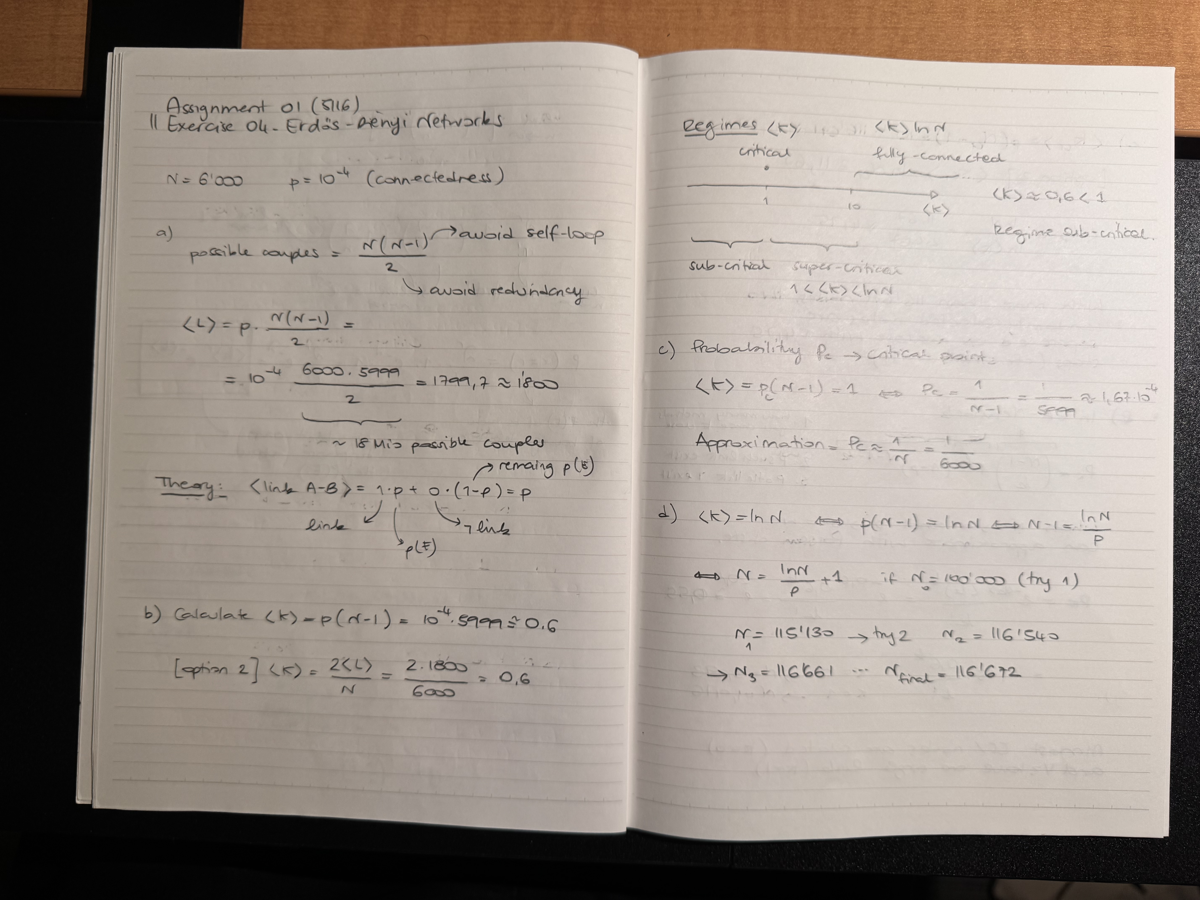

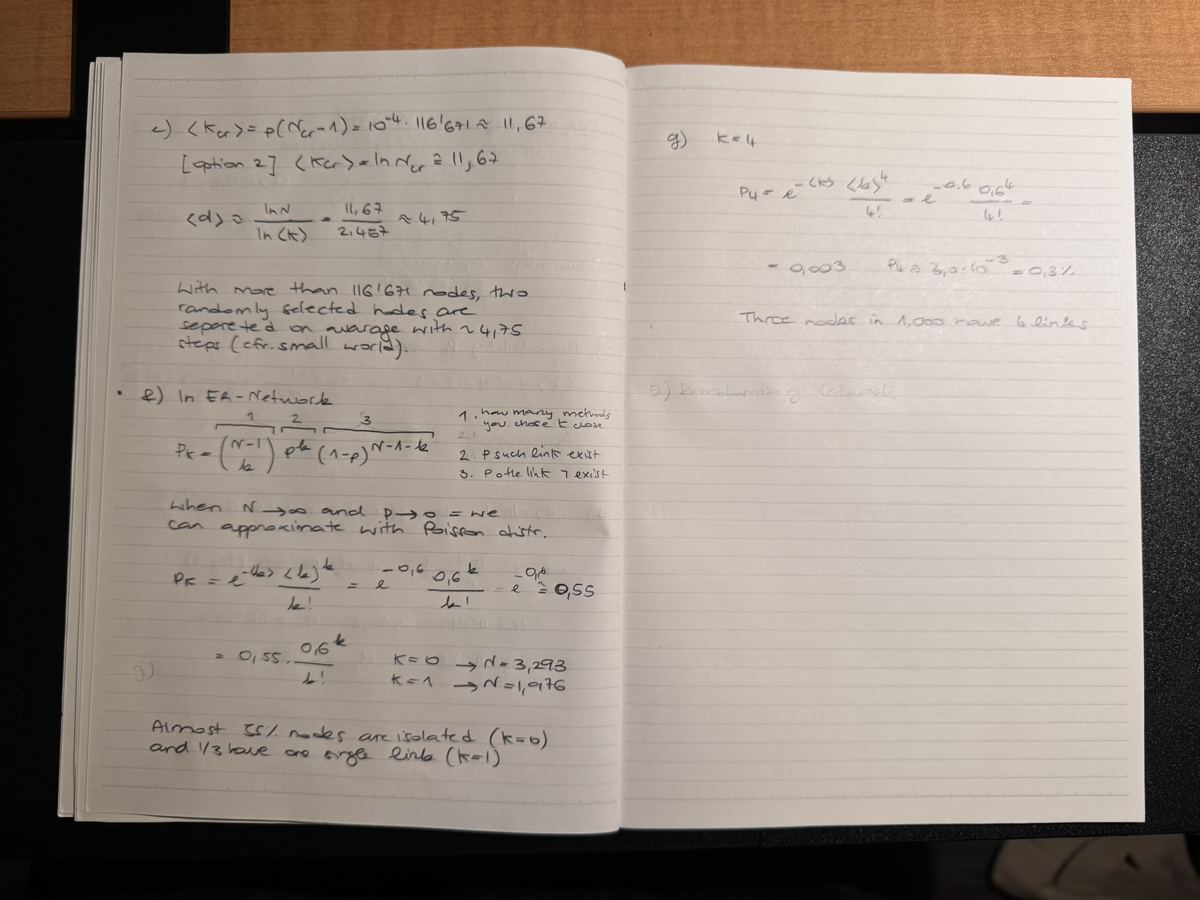

In [37]:
register_heif_opener()   # lets PIL open .HEIC files

folder = "/Users/jac/Library/Mobile Documents/com~apple~CloudDocs/Desktop/PHD/CLASSES/FALL_2026/NETS5116/01_Assignment/"
files = ["IMG_5700.HEIC", "IMG_5701.HEIC"]

for f in files:
    img = Image.open(folder + f)
    img.thumbnail((1200, 1200))   # resize so it fits in the notebook
    display(img)

## Question 05 – Randomizing a network

In [19]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

Graph with 1574 nodes and 17215 edges
False False
Graph with 1574 nodes and 17215 edges


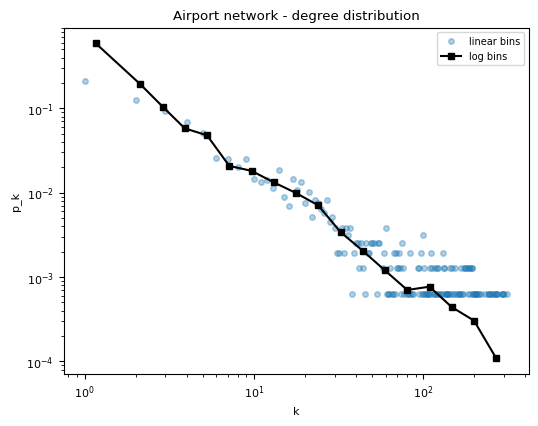

avg degree: 21.87 | max degree: 314
global clustering (transitivity): 0.3841
average clustering: 0.5042


In [21]:
# load the airport network
G_air = nx.read_gml("airport-network.gml")
print(G_air)
print(G_air.is_directed(), G_air.is_multigraph())

# make it simple + undirected (needed for clustering)
G_air = nx.Graph(G_air)
G_air.remove_edges_from(nx.selfloop_edges(G_air))
print(G_air)

# degree distribution
degrees = [d for n, d in G_air.degree()]
N = len(G_air)
counts = Counter(degrees)

k = np.array(sorted(x for x in counts if x > 0))   # no k=0 on log scale
pk = np.array([counts[x] / N for x in k])

# log bins, because the tail is very noisy
bins = np.logspace(0, np.log10(max(degrees)), 20)
hist, edges = np.histogram(degrees, bins=bins)
pk_log = hist / (N * np.diff(edges))
centers = np.sqrt(edges[:-1] * edges[1:])

plt.figure(figsize=(6, 4.5))
plt.loglog(k, pk, "o", alpha=0.35, ms=4, label="linear bins")
plt.loglog(centers[pk_log > 0], pk_log[pk_log > 0], "s-", color="black", ms=5, label="log bins")
plt.xlabel("k")
plt.ylabel("p_k")
plt.title("Airport network - degree distribution")
plt.legend()
plt.show()

print("avg degree:", round(np.mean(degrees), 2), "| max degree:", max(degrees))

# clustering
print("global clustering (transitivity):", round(nx.transitivity(G_air), 4))
print("average clustering:", round(nx.average_clustering(G_air), 4))

Graph with 1574 nodes and 17215 edges


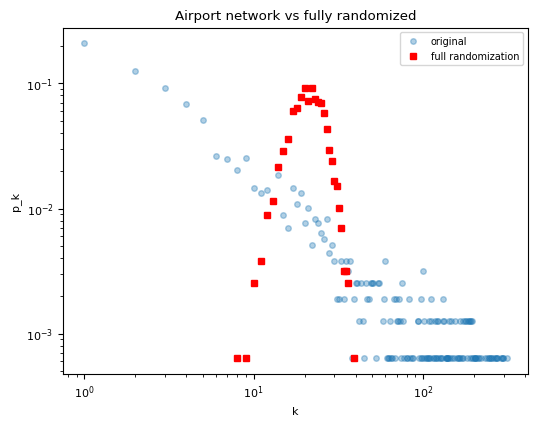

avg degree: 21.87 | max degree: 39
global clustering (random): 0.014
global clustering (original): 0.3841
expected for ER, <k>/N: 0.0139


In [22]:
# full randomization: same N and L, links placed at random (ER network)
N = G_air.number_of_nodes()
L = G_air.number_of_edges()
G_rand = nx.gnm_random_graph(N, L, seed=42)
print(G_rand)

# degree distribution of the randomized network
deg_rand = [d for n, d in G_rand.degree()]
counts_rand = Counter(deg_rand)
k_rand = np.array(sorted(x for x in counts_rand if x > 0))
pk_rand = np.array([counts_rand[x] / N for x in k_rand])

# plot original vs randomized
plt.figure(figsize=(6, 4.5))
plt.loglog(k, pk, "o", alpha=0.35, ms=4, label="original")
plt.loglog(k_rand, pk_rand, "s", color="red", ms=4, label="full randomization")
plt.xlabel("k")
plt.ylabel("p_k")
plt.title("Airport network vs fully randomized")
plt.legend()
plt.show()

print("avg degree:", round(np.mean(deg_rand), 2), "| max degree:", max(deg_rand))

# clustering after randomization
print("global clustering (random):", round(nx.transitivity(G_rand), 4))
print("global clustering (original):", round(nx.transitivity(G_air), 4))
print("expected for ER, <k>/N:", round(np.mean(deg_rand) / N, 4))

Graph with 1574 nodes and 17215 edges
same degrees: True


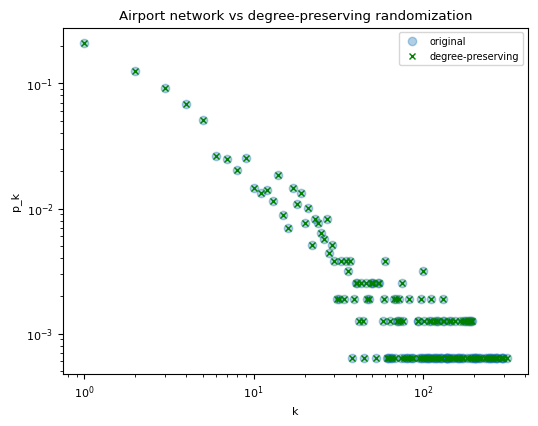

global clustering (degree-preserving): 0.2329
global clustering (full random): 0.014
global clustering (original): 0.3841


In [24]:
# degree-preserving randomization: swap link ends, every node keeps its degree
G_dp = G_air.copy()
L = G_dp.number_of_edges()
nx.double_edge_swap(G_dp, nswap=10 * L, max_tries=100 * L, seed=42)
print(G_dp)

# check that degrees are really unchanged
print("same degrees:", dict(G_dp.degree()) == dict(G_air.degree()))

# degree distribution (should be identical to the original)
deg_dp = [d for n, d in G_dp.degree()]
counts_dp = Counter(deg_dp)
k_dp = np.array(sorted(x for x in counts_dp if x > 0))
pk_dp = np.array([counts_dp[x] / N for x in k_dp])

plt.figure(figsize=(6, 4.5))
plt.loglog(k, pk, "o", alpha=0.35, ms=6, label="original")
plt.loglog(k_dp, pk_dp, "x", color="green", ms=4, label="degree-preserving")
plt.xlabel("k")
plt.ylabel("p_k")
plt.title("Airport network vs degree-preserving randomization")
plt.legend()
plt.show()

# clustering
print("global clustering (degree-preserving):", round(nx.transitivity(G_dp), 4))
print("global clustering (full random):", round(nx.transitivity(G_rand), 4))
print("global clustering (original):", round(nx.transitivity(G_air), 4))

In [25]:
for name, g in [("original", G_air), ("full random", G_rand), ("degree-preserving", G_dp)]:
    d = [x for n, x in g.degree()]
    print(f"{name:18s} <k> = {np.mean(d):.2f}  k_max = {max(d):4d}  C = {nx.transitivity(g):.4f}")

original           <k> = 21.87  k_max =  314  C = 0.3841
full random        <k> = 21.87  k_max =   39  C = 0.0140
degree-preserving  <k> = 21.87  k_max =  314  C = 0.2329


**Comparison between the original network and the two randomizations**

**Degree distribution.** The average degree is the same in all three cases (21.87), which makes sense because both randomizations keep N and L fixed. What changes is the shape of the distribution. In the original network a few airports work as big hubs (up to 314 connections), while most airports have only a few links. On the log-log plot this gives a long tail over more than two orders of magnitude. With full randomization the network becomes basically an Erdős–Rényi graph: degrees stay close to the mean, the hubs are gone, and the max degree goes down to 39. With degree-preserving randomization the distribution does not change at all, since every node keeps its degree, so the points are exactly on top of the original ones.

**Clustering.** The original network has a pretty high clustering, C = 0.384. In practice, if two airports are both connected to the same airport, there is a good chance they are also connected to each other. Full randomization almost completely destroys this: C goes down to 0.014, which is what we would expect from a random network. Degree-preserving randomization is in the middle, with C = 0.233, so about more than the half of the clustering is still there.

**What I take from this.** Comparing the three networks helps to understand where the clustering comes from. Going from 0.014 to 0.233 just by keeping the degrees means that a large part of the clustering is explained by the hubs: they are connected to so many airports that triangles appear around them even at random. But there is still a gap between 0.233 and 0.384, roughly less than the half of the original clustering, that the degree distribution alone does not explain. My interpretation is that this part comes from geography and from how air traffic is organized, since airports in the same region tend to be connected to each other and form local triangles, with the hubs linking the different regions.

## Question 06 – Watts & Strogatz, 1998

p = 0.0001  C/C0 = 1.000  L/L0 = 0.938
p = 0.0002  C/C0 = 0.999  L/L0 = 0.846
p = 0.0004  C/C0 = 0.999  L/L0 = 0.749
p = 0.0008  C/C0 = 0.997  L/L0 = 0.583
p = 0.0017  C/C0 = 0.995  L/L0 = 0.435
p = 0.0035  C/C0 = 0.990  L/L0 = 0.281
p = 0.0070  C/C0 = 0.980  L/L0 = 0.209
p = 0.0143  C/C0 = 0.958  L/L0 = 0.153
p = 0.0289  C/C0 = 0.919  L/L0 = 0.122
p = 0.0588  C/C0 = 0.839  L/L0 = 0.100
p = 0.1194  C/C0 = 0.692  L/L0 = 0.085
p = 0.2424  C/C0 = 0.445  L/L0 = 0.074
p = 0.4924  C/C0 = 0.140  L/L0 = 0.067
p = 1.0000  C/C0 = 0.013  L/L0 = 0.065


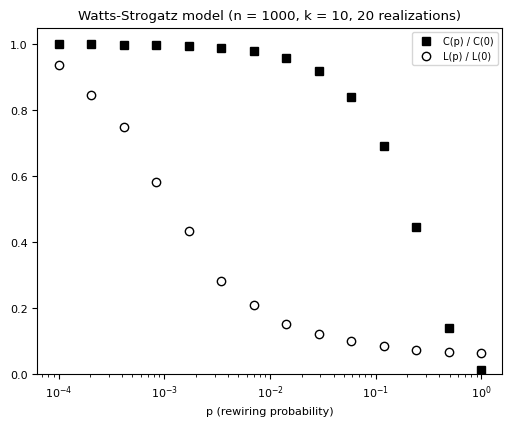

In [27]:
# same parameters as Watts & Strogatz (1998)
n = 1000      # nodes
k = 10        # each node connected to k nearest neighbours on the ring
reps = 20     # realizations averaged for each p
ps = np.logspace(-4, 0, 14)   # rewiring probability from 0.0001 to 1

# reference values for the regular ring lattice (p = 0)
G0 = nx.watts_strogatz_graph(n, k, 0)
C0 = nx.average_clustering(G0)
L0 = nx.average_shortest_path_length(G0)

C_p, L_p = [], []
for p in ps:
    C_list, L_list = [], []
    for r in range(reps):
        # "connected" version so the path length is always defined
        G = nx.connected_watts_strogatz_graph(n, k, p, seed=r)
        C_list.append(nx.average_clustering(G))
        L_list.append(nx.average_shortest_path_length(G))
    C_p.append(np.mean(C_list) / C0)
    L_p.append(np.mean(L_list) / L0)
    print(f"p = {p:.4f}  C/C0 = {C_p[-1]:.3f}  L/L0 = {L_p[-1]:.3f}")

plt.figure(figsize=(6, 4.5))
plt.semilogx(ps, C_p, "s", color="black", label="C(p) / C(0)")
plt.semilogx(ps, L_p, "o", color="black", markerfacecolor="white", label="L(p) / L(0)")
plt.xlabel("p (rewiring probability)")
plt.ylim(0, 1.05)
plt.title(f"Watts-Strogatz model (n = {n}, k = {k}, {reps} realizations)")
plt.legend()
plt.show()

**Key insights.** The figure shows the clustering C(p) and the average path length L(p) as the rewiring probability p goes from 0 to 1 (random network), both normalized by their values at p = 0. The key point is that the two curves drop at very different values of p. The path length falls very fast: rewiring even a tiny fraction of links already brings L close to the value of a random network, because each rewired link works as a shortcut between distant parts of the ring. Clustering instead stays almost unchanged until p is much larger, since rewiring a few links barely affects the local triangles. Between these two points there is a wide range of p where the network has both high clustering, like a regular lattice, and short paths, like a random network. This is the small-world regime. It shows that a few random long-range links are enough to make a "large" world small, which is consistent with what we observe in many real networks like social or neural ones.